In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

In [3]:
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)

    ax = ax or plt.gca()

    th = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)

    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")

    ax.set_aspect("equal")
    ax.legend()
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")

    return z, p

In [4]:
b = [1, 1]
a = [1, -0.75, 0.125]

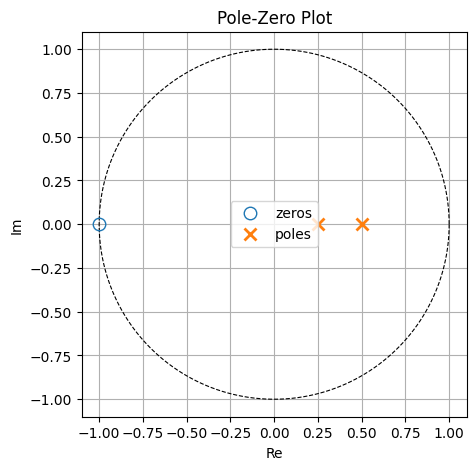

Zeros: [-1.]
Poles: [0.5  0.25]


In [5]:
fig, ax = plt.subplots(figsize=(5, 5))

z, p = zplane(b, a, ax)

plt.title("Pole-Zero Plot")
plt.grid()
plt.show()

print("Zeros:", z)
print("Poles:", p)

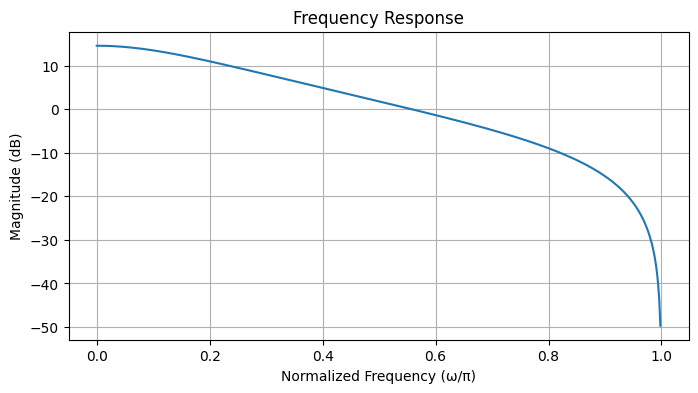

In [6]:
w, H = signal.freqz(b, a, worN=512)

plt.figure(figsize=(8, 4))
plt.plot(w/np.pi, 20*np.log10(np.abs(H)))

plt.title("Frequency Response")
plt.xlabel("Normalized Frequency (ω/π)")
plt.ylabel("Magnitude (dB)")
plt.grid()
plt.show()

In [7]:
stable = np.all(np.abs(p) < 1)

print("Poles:", p)
print("Pole magnitudes:", np.abs(p))
print("System is stable:", stable)

Poles: [0.5  0.25]
Pole magnitudes: [0.5  0.25]
System is stable: True


### Observation – Task 4.1

The pole-zero plot shows one zero at -1 and two poles at 0.5 and 0.25. Both poles lie inside the unit circle, indicating that the system is stable. The frequency response graph illustrates how the system responds to different frequencies. The stability test returned `True`, confirming that all poles have magnitudes less than one.

Task 4.2: Inverse Z-transform using residuez

In [8]:
b = [1]
a = [1, -0.75, 0.125]

In [9]:
r, p, k = signal.residuez(b, a)

print("Residues:", r)
print("Poles:", p)
print("Direct term:", k)

Residues: [-1.  2.]
Poles: [0.25 0.5 ]
Direct term: []


In [10]:
n = np.arange(10)

x = -1*(0.25**n) + 2*(0.5**n)

print("Time indices:", n)
print("Inverse Z-transform:", x)

Time indices: [0 1 2 3 4 5 6 7 8 9]
Inverse Z-transform: [1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]


In [11]:
impulse = np.zeros(10)
impulse[0] = 1

x_filter = signal.lfilter(b, a, impulse)

print("Inverse Z-transform:", x)
print("Using lfilter():", x_filter)

print("Results match:", np.allclose(x, x_filter))

Inverse Z-transform: [1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]
Using lfilter(): [1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]
Results match: True


In [12]:
b = [1, 1]
a = [1, -0.75, 0.125]

r, p, k = signal.residuez(b, a)

print("Residues:", r)
print("Poles:", p)

Residues: [-5.  6.]
Poles: [0.25 0.5 ]


In [13]:
n = np.arange(10)

h = 6*(0.5**n) - 5*(0.25**n)

impulse = np.zeros(10)
impulse[0] = 1

h_filter = signal.lfilter(b, a, impulse)

print("Inverse Z-transform:", h)
print("Using lfilter():", h_filter)
print("Results match:", np.allclose(h, h_filter))

Inverse Z-transform: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Using lfilter(): [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Results match: True


### Observation – Task 4.2

The `signal.residuez()` function was used to calculate the residues and poles of the given systems. The inverse Z-transform was obtained using partial fraction expansion. The resulting sequences were compared with the output of `signal.lfilter()`. Both methods produced matching results, and the verification returned `True`. This confirms the correctness of the inverse Z-transform calculations.

Task 4.3: Pole Position and Impulse Response

In [14]:
r_values = [0.5, 0.8, 0.95, 1.0, 1.05]

print("Pole magnitudes to be tested:", r_values)

Pole magnitudes to be tested: [0.5, 0.8, 0.95, 1.0, 1.05]


In [15]:
n = np.arange(40)

impulse = np.zeros(40)
impulse[0] = 1

In [16]:
for r in r_values:
    a = [1, -2*r*np.cos(np.pi/4), r**2]
    print("r =", r, " Denominator coefficients:", a)

r = 0.5  Denominator coefficients: [1, np.float64(-0.7071067811865476), 0.25]
r = 0.8  Denominator coefficients: [1, np.float64(-1.1313708498984762), 0.6400000000000001]
r = 0.95  Denominator coefficients: [1, np.float64(-1.3435028842544403), 0.9025]
r = 1.0  Denominator coefficients: [1, np.float64(-1.4142135623730951), 1.0]
r = 1.05  Denominator coefficients: [1, np.float64(-1.48492424049175), 1.1025]


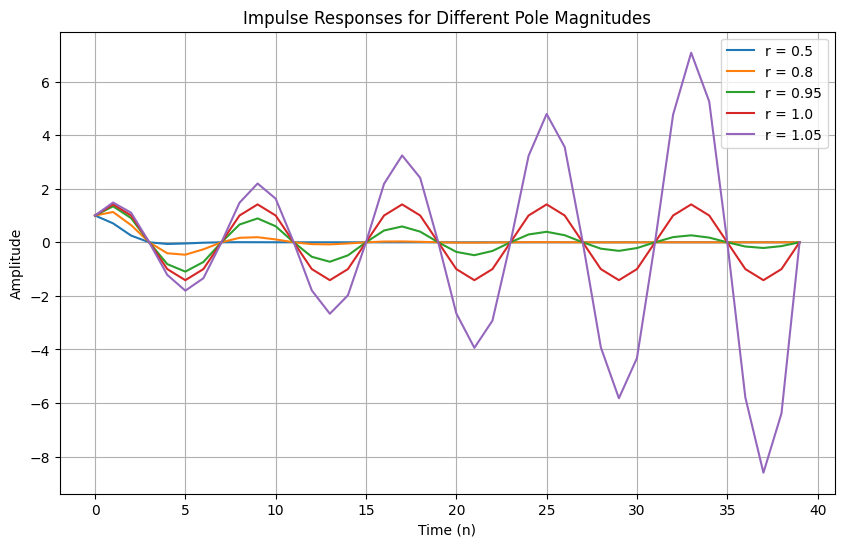

In [17]:
plt.figure(figsize=(10, 6))

for r in r_values:
    a = [1, -2*r*np.cos(np.pi/4), r**2]

    h = signal.lfilter([1], a, impulse)

    plt.plot(n, h, label=f"r = {r}")

plt.title("Impulse Responses for Different Pole Magnitudes")
plt.xlabel("Time (n)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

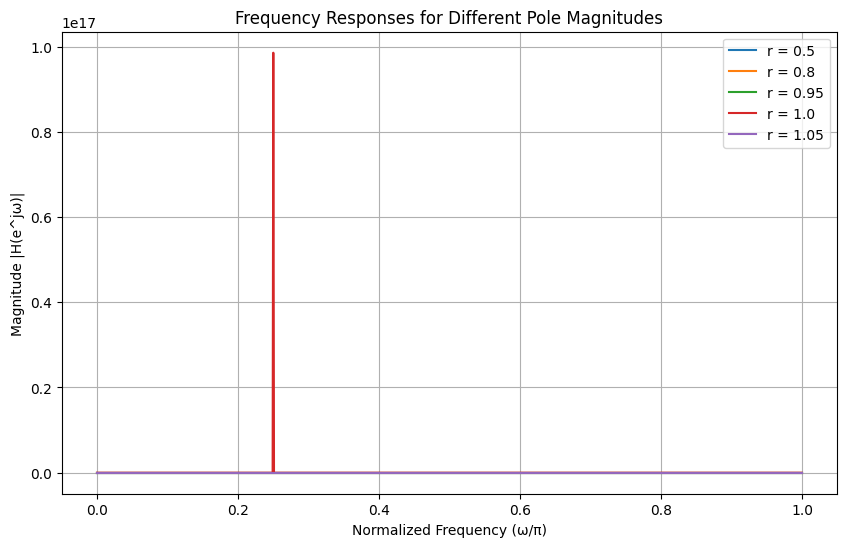

In [18]:
plt.figure(figsize=(10, 6))

for r in r_values:
    a = [1, -2*r*np.cos(np.pi/4), r**2]

    w, H = signal.freqz([1], a, worN=1024)

    plt.plot(w/np.pi, np.abs(H), label=f"r = {r}")

plt.title("Frequency Responses for Different Pole Magnitudes")
plt.xlabel("Normalized Frequency (ω/π)")
plt.ylabel("Magnitude |H(e^jω)|")
plt.legend()
plt.grid()
plt.show()

In [19]:
for r in r_values:
    a = [1, -2*r*np.cos(np.pi/4), r**2]

    poles = np.roots(a)
    stable = np.all(np.abs(poles) < 1)

    print(
        f"r = {r}: "
        f"Pole magnitudes = {np.abs(poles)}, "
        f"Stable = {stable}"
    )

r = 0.5: Pole magnitudes = [0.5 0.5], Stable = True
r = 0.8: Pole magnitudes = [0.8 0.8], Stable = True
r = 0.95: Pole magnitudes = [0.95 0.95], Stable = True
r = 1.0: Pole magnitudes = [1. 1.], Stable = False
r = 1.05: Pole magnitudes = [1.05 1.05], Stable = False


### Observation – Task 4.3

The experiment demonstrated that pole positions have a significant effect on impulse response, frequency response and system stability.

For r = 0.5, 0.8 and 0.95, the impulse responses decay with time, indicating stable systems. As r approaches 1, the decay becomes slower and the resonance peak becomes sharper.

At r = 1.0, the poles lie on the unit circle, resulting in sustained oscillations and an unstable system in the BIBO sense. At r = 1.05, the poles lie outside the unit circle, causing the impulse response to grow with time.

Therefore, systems with all poles strictly inside the unit circle are stable.

Task 4.4: Stability of Systems

In [20]:
systems = {
    "H1": ([1], [1, -1.6, 0.89]),
    "H2": ([1, 1], [1, -2.5, 1]),
    "H3": ([1], [1, 0.5, -0.5]),
    "H4": ([1, 0, 0, 0, -1], [1])
}

print("Four systems successfully defined.")

Four systems successfully defined.


In [21]:
for name, (b, a) in systems.items():
    z, p, k = signal.tf2zpk(b, a)

    print(f"\n{name}")
    print("Zeros:", z)
    print("Poles:", p)
    print("Pole magnitudes:", np.abs(p))


H1
Zeros: []
Poles: [0.8+0.5j 0.8-0.5j]
Pole magnitudes: [0.94339811 0.94339811]

H2
Zeros: [-1.]
Poles: [2.  0.5]
Pole magnitudes: [2.  0.5]

H3
Zeros: []
Poles: [-1.   0.5]
Pole magnitudes: [1.  0.5]

H4
Zeros: [-1.00000000e+00+0.j  8.32667268e-17+1.j  8.32667268e-17-1.j
  1.00000000e+00+0.j]
Poles: []
Pole magnitudes: []


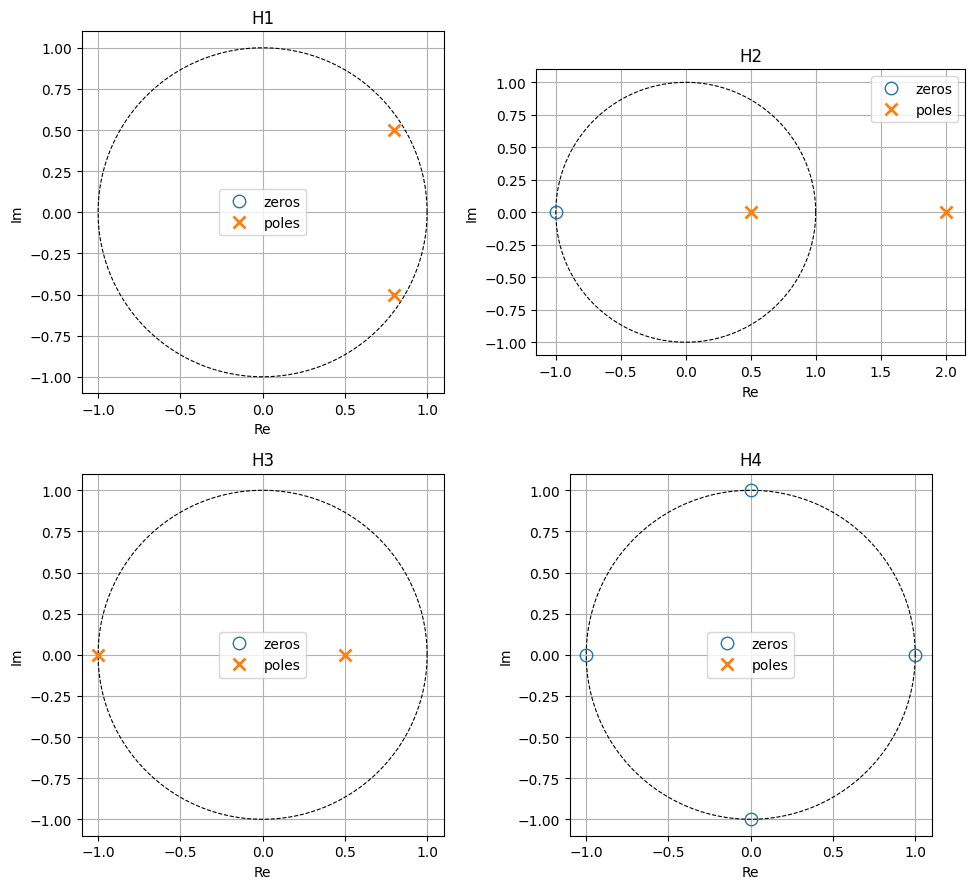

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9))

for ax, (name, (b, a)) in zip(axes.flat, systems.items()):
    z, p = zplane(b, a, ax)
    ax.set_title(name)
    ax.grid()

plt.tight_layout()
plt.show()

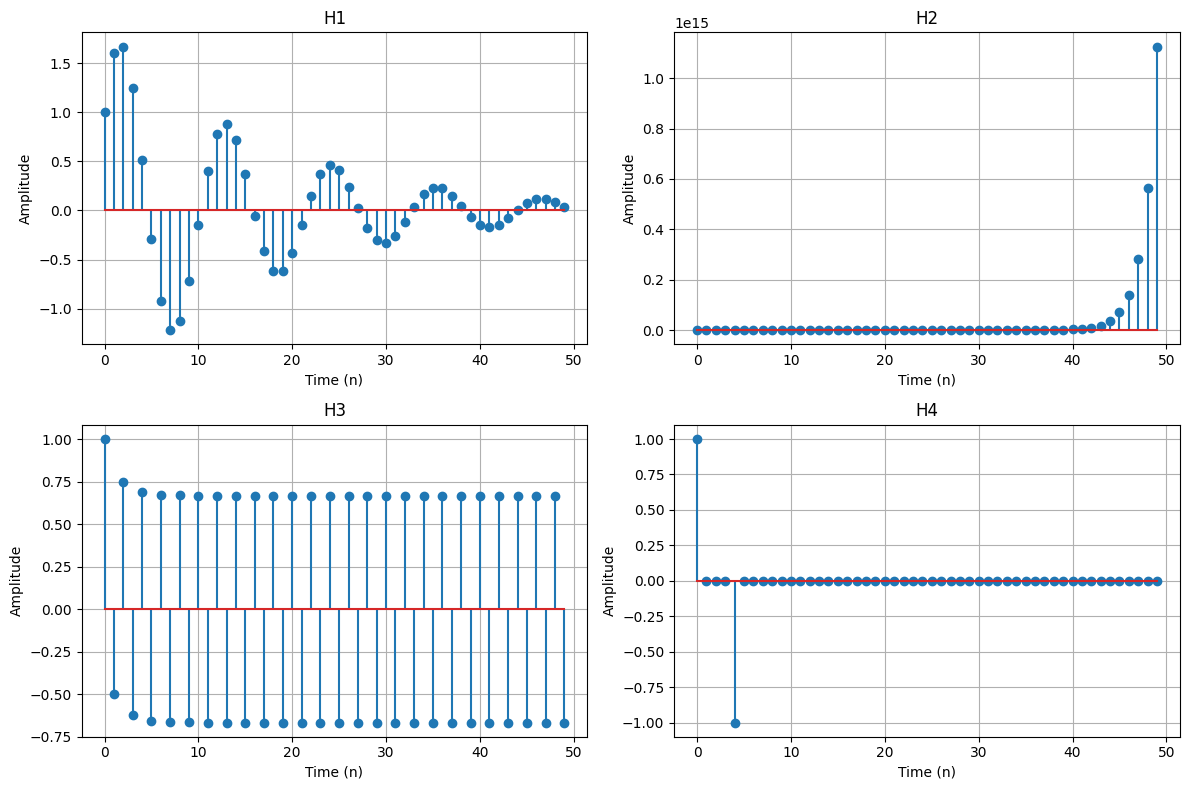

In [23]:
n = np.arange(50)

impulse = np.zeros(50)
impulse[0] = 1

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (name, (b, a)) in zip(axes.flat, systems.items()):
    h = signal.lfilter(b, a, impulse)

    ax.stem(n, h)
    ax.set_title(name)
    ax.set_xlabel("Time (n)")
    ax.set_ylabel("Amplitude")
    ax.grid()

plt.tight_layout()
plt.show()

In [24]:
for name, (b, a) in systems.items():
    z, p, k = signal.tf2zpk(b, a)

    if len(p) == 0:
        stable = True
    else:
        stable = np.all(np.abs(p) < 1)

    print(f"{name}: Stable = {stable}")

H1: Stable = True
H2: Stable = False
H3: Stable = False
H4: Stable = True


### Observation – Task 4.4

The stability of four different systems was investigated using pole-zero plots and impulse responses.

- H1 was stable because all its poles lie inside the unit circle. Its impulse response decays with time.
- H2 was unstable because one pole lies outside the unit circle, causing its impulse response to grow.
- H3 was unstable because one pole lies exactly on the unit circle, producing sustained oscillations.
- H4 was stable because it is an FIR system with a finite-duration impulse response.

The Python stability test produced the expected results: H1 and H4 were stable, while H2 and H3 were unstable. This experiment demonstrated the relationship between pole positions and system stability.

In [25]:
fs = 8000
f0 = 1000
r = 0.97

theta = 2*np.pi*f0/fs

print("Sampling frequency:", fs, "Hz")
print("Resonance frequency:", f0, "Hz")
print("Pole radius:", r)
print("Pole angle:", theta)

Sampling frequency: 8000 Hz
Resonance frequency: 1000 Hz
Pole radius: 0.97
Pole angle: 0.7853981633974483


In [26]:
b = [1, 0, -1]

a = [
    1,
    -2*r*np.cos(theta),
    r**2
]

print("Numerator coefficients:", b)
print("Denominator coefficients:", a)

Numerator coefficients: [1, 0, -1]
Denominator coefficients: [1, np.float64(-1.3717871555019023), 0.9409]


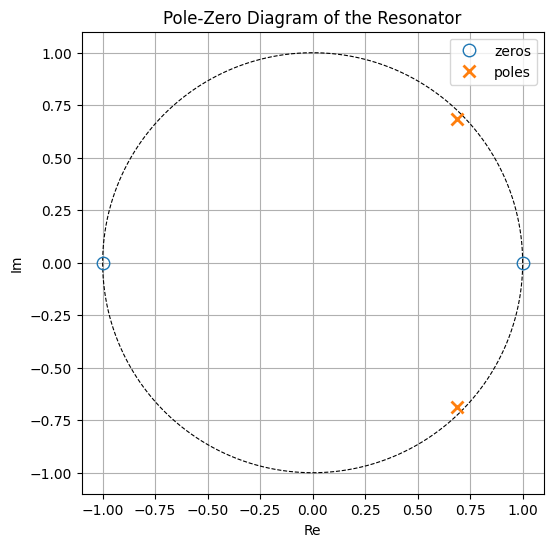

Zeros: [-1.  1.]
Poles: [0.68589358+0.68589358j 0.68589358-0.68589358j]


In [27]:
fig, ax = plt.subplots(figsize=(6, 6))

zeros, poles = zplane(b, a, ax)

ax.set_title("Pole-Zero Diagram of the Resonator")
ax.grid(True)

plt.show()

print("Zeros:", zeros)
print("Poles:", poles)

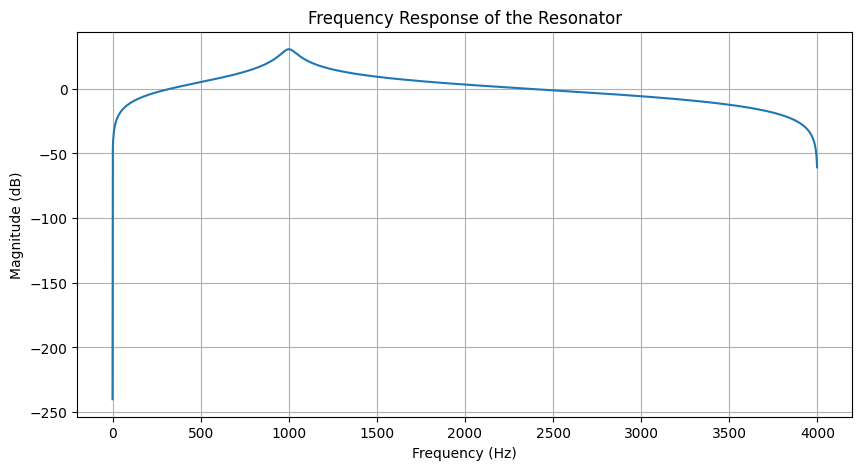

In [28]:
w, H = signal.freqz(b, a, worN=2048, fs=fs)

plt.figure(figsize=(10, 5))

plt.plot(w, 20*np.log10(np.maximum(np.abs(H), 1e-12)))

plt.title("Frequency Response of the Resonator")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.grid(True)

plt.show()

In [29]:
# Generate 2 seconds of white noise
rng = np.random.default_rng(0)
x = rng.normal(0, 1, fs * 2)

# Apply the resonator
y = signal.lfilter(b, a, x)

print("Input signal length:", len(x))
print("Output signal length:", len(y))

Input signal length: 16000
Output signal length: 16000


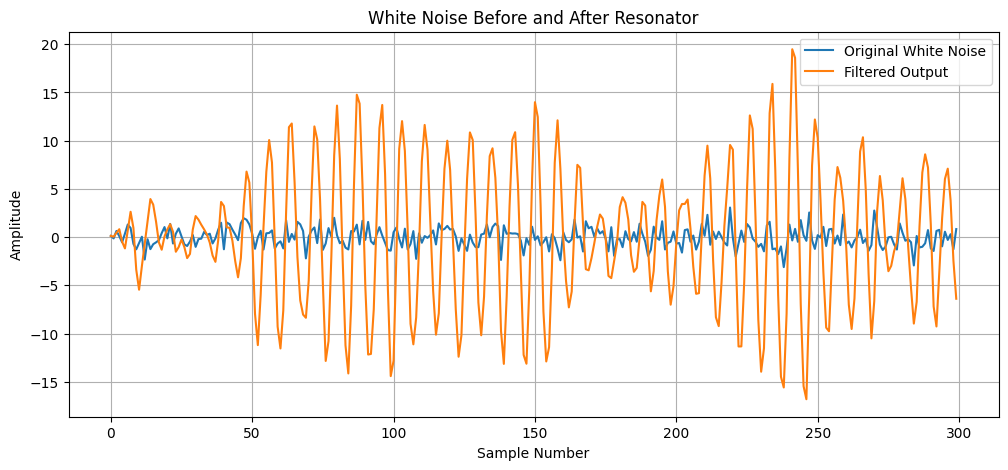

In [30]:
plt.figure(figsize=(12, 5))

plt.plot(x[:300], label="Original White Noise")
plt.plot(y[:300], label="Filtered Output")

plt.title("White Noise Before and After Resonator")
plt.xlabel("Sample Number")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)

plt.show()

In [31]:
from IPython.display import Audio, display

display(Audio(y, rate=fs))

**Observation – Task 4.5: Design a Resonator**

A second-order resonator was designed with a resonance frequency of 1 kHz, sampling frequency of 8 kHz and pole radius of 0.97. Zeros were placed at z = +1 and z = -1 to suppress DC and the Nyquist frequency (4 kHz). The pole-zero diagram showed that both poles lie inside the unit circle, confirming that the system is stable. The frequency response showed a resonance peak around 1 kHz. White noise was generated and passed through the resonator using `signal.lfilter()`. The filtered output was plotted and played successfully. This demonstrated how a resonator emphasizes frequencies around its resonance frequency.

# WEEK 4: ANALYSIS QUESTIONS AND ANSWERS

### Question 1: Explain the effect of r on the bandwidth of resonance in Task 4.3.

**Answer:**

The pole radius, r, controls the bandwidth of resonance. When r is small, the resonance peak is broad and the bandwidth is wide. As r increases towards 1, the resonance peak becomes sharper and narrower, meaning that the bandwidth decreases. Therefore, a larger pole radius produces a more selective resonator with a narrower bandwidth.

### Question 2: What happens to h(n) when a pole lies exactly on the unit circle?

**Answer:**

When a pole lies exactly on the unit circle, the impulse response does not decay with time. For complex conjugate poles, the impulse response produces sustained oscillations. This means that the impulse response is not absolutely summable, and the system is not BIBO stable.

### Question 3: Why does placing zeros at z = ±1 make the resonator a band-pass filter?

**Answer:**

Placing zeros at z = +1 and z = -1 makes the frequency response zero at DC (0 Hz) and the Nyquist frequency (fs/2). These zeros suppress very low and highest representable frequencies, while the poles create a resonance peak around 1 kHz. Therefore, the resonator behaves like a band-pass filter by emphasizing frequencies around its resonance frequency.

### Question 4: Use the stability triangle (handout Example 2.4) to check your answers to Task 4.4 (a)–(c).

**Answer:**

For a second-order system with denominator:

H(z) = 1 + a₁z⁻¹ + a₂z⁻²

The stability conditions are:

1. 1 + a₁ + a₂ > 0
2. 1 − a₁ + a₂ > 0
3. 1 − a₂ > 0

**System H1:**

Denominator: 1 − 1.6z⁻¹ + 0.89z⁻²

- a₁ = −1.6, a₂ = 0.89
- 1 + a₁ + a₂ = 0.29 > 0
- 1 − a₁ + a₂ = 3.49 > 0
- 1 − a₂ = 0.11 > 0

All conditions are satisfied. Therefore, H1 is **stable**.

**System H2:**

Denominator: 1 − 2.5z⁻¹ + z⁻²

- a₁ = −2.5, a₂ = 1
- 1 + a₁ + a₂ = −0.5 < 0
- 1 − a₁ + a₂ = 4.5 > 0
- 1 − a₂ = 0

The strict stability conditions are not satisfied. Therefore, H2 is **unstable**.

**System H3:**

Denominator: 1 + 0.5z⁻¹ − 0.5z⁻²

- a₁ = 0.5, a₂ = −0.5
- 1 + a₁ + a₂ = 1 > 0
- 1 − a₁ + a₂ = 0
- 1 − a₂ = 1.5 > 0

The second condition is not strictly satisfied. Therefore, H3 is **unstable**, because one pole lies exactly on the unit circle.

**Conclusion:**

The stability triangle confirms the results obtained from the pole-zero diagrams in Task 4.4. H1 is stable, while H2 and H3 are unstable.

## AI USE STATEMENT

Artificial Intelligence (AI) tools, particularly ChatGPT, were used as learning assistants during this laboratory assignment. AI assistance was used to explain Digital Signal Processing concepts, guide Python code implementation, troubleshoot errors, and interpret graphical outputs.

All code was executed and tested by the student using Python in Google Colab. The student reviewed the results, interpreted the observations, and prepared the final laboratory work.

AI was used to support learning and understanding, while the practical implementation and verification were performed by the student.